In [59]:
import numpy as np

np.random.seed(42)

#generate the composition of soil
sand = np.random.uniform(0, 100, 1000)
clay = np.random.uniform(0, 100-sand, 1000)
silt = 100 - sand - clay

#generate the properties of soil
ph = np.random.uniform(4, 9, 1000)
organic_matter = np.random.uniform(0, 10, 1000)

#combine them
X = np.column_stack([
    sand, silt, clay, ph, organic_matter
])

print(X)

[[37.45401188 50.96666615 11.57932197  5.30852842  6.72702994]
 [95.07143064  2.25777295  2.6707964   5.234894    7.96681397]
 [73.19939418  3.40512857 23.39547725  8.5312729   2.50467899]
 ...
 [13.68186309 80.36580941  5.9523275   5.5489393   3.94572315]
 [95.02373538  4.69234523  0.28391939  5.45022766  5.29940587]
 [44.6005773  39.76642167 15.63300103  8.35707017  1.61367358]]


In [60]:
labels = []

for i in range(len(X)):
    if clay[i] >= 40:
        labels.append(0)       # Clay
    elif sand[i] >= 60:
        labels.append(1)       # Sand
    elif silt[i] >= 50:
        labels.append(3)       # Silt
    else:
        labels.append(2)       # Loam

y = np.array(labels)

print("Feature shape:", X.shape)
print("Label shape:", y.shape)
print("Class counts:", np.bincount(y))

Feature shape: (1000, 5)
Label shape: (1000,)
Class counts: [253 387 204 156]


In [ ]:
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Xtr, Xte, ytr, yte = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
Xtr = scaler.fit_transform(Xtr)
Xte = scaler.transform(Xte)

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", dev)

Xtr = torch.tensor(Xtr, dtype=torch.float32, device=dev)
Xte = torch.tensor(Xte, dtype=torch.float32, device=dev)

ytr = torch.tensor(ytr, dtype=torch.long, device=dev)
yte = torch.tensor(yte, dtype=torch.long, device=dev)

Using device: cuda


In [62]:
import torch.nn as nn

net = nn.Sequential(
    nn.Linear(5, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 4)
).to(dev)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.001)

In [66]:
epochs = 500
loss_history = []
accuracy_history = []

for e in range(epochs):
    outputs = net(Xtr)
    loss = loss_fn(outputs, ytr)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    predictions = outputs.argmax(dim=1)
    accuracy = (predictions == ytr).float().mean()

    loss_history.append(loss.item())
    accuracy_history.append(accuracy.item())

    if (e+1) % 100 == 0:
        print(
            f"Epoch {e+1}: "
            f"Loss={loss.item():.4f}, "
            f"Accuracy={accuracy.item():.4f}"
        )

Epoch 100: Loss=0.0707, Accuracy=0.9862
Epoch 200: Loss=0.0561, Accuracy=0.9900
Epoch 300: Loss=0.0456, Accuracy=0.9937
Epoch 400: Loss=0.0380, Accuracy=0.9950
Epoch 500: Loss=0.0319, Accuracy=0.9950


In [67]:
net.eval()

with torch.no_grad():
    outputs = net(Xte)
    predictions = outputs.argmax(dim=1)

    test_accuracy = (predictions == yte).float().mean()

print("Test Accuracy:", test_accuracy.item())

Test Accuracy: 0.9549999833106995


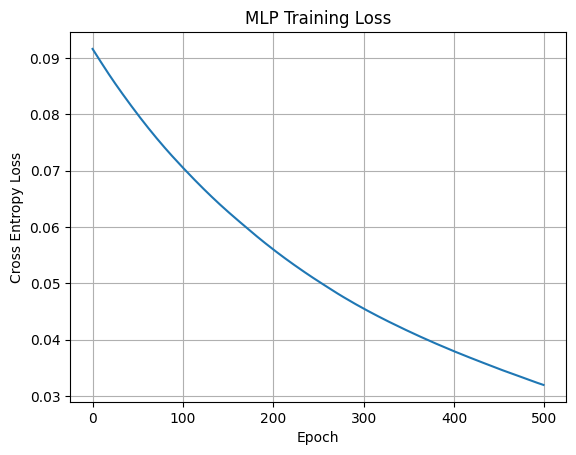

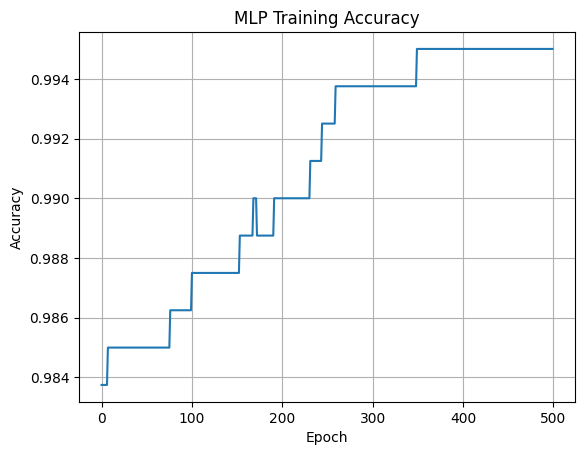

In [68]:
import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("MLP Training Loss")
plt.grid(True)
plt.show()

plt.plot(accuracy_history)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Training Accuracy")
plt.grid(True)
plt.show()